# Phase 3 · NB10 · TREAD-TWO train-only appearance/reference gate

**386 existing training images · frozen selected v1 · seven probes · zero optimizer updates.**

NB09 is complete and HF-verified. This next gate examines appearance stability,
a fixed local-contrast feature proposal and a reference bank drawn from more
distinct existing training photos. It never queries validation/test pixels.
The candidate bank is **UNTRAINED** and is not installed in NB08 or a workstation.

## Kaggle settings and order

1. Select **GPU T4 ×2**, **Internet ON**.
2. Attach exactly one **expanded** `shanmuk4622/tire-dataset-prepared-phase2`
   dataset directly from Kaggle. It stays read-only; no new photos are needed.
3. Keep at least **4 GiB free** for native atlas/CSV state and publication staging.
   The total output guard is 16 GB within the user's 20 GB working-output budget.
4. Enable Kaggle Secret **HF_TOKEN** with write access to
   `Shanmuk4622/tyre-wear-study` for the execution/publication cell.
5. **Run All.** The tested Hub client is pinned; Torch/CUDA are not changed.

GPU0 performs the frozen original-frame dense pass once per training image.
GPU1 runs the frozen selected epoch18 patch classifier and feature diagnostics.
Both remain eval/FP32 with gradients disabled. This is a probe, not another fit.
The one-GPU local recovery check is distinct from actual Kaggle dual-T4 execution.


In [1]:
import base64,hashlib,importlib.metadata,json,os,signal,subprocess,sys,time,shutil
from pathlib import Path
from filelock import FileLock
assert Path('/kaggle/working').exists(),'Run NB10 on Kaggle.'
WORK=Path('/kaggle/working/tread_two_nb10_appearance_gate')
WORK.mkdir(parents=True,exist_ok=True)
assert shutil.disk_usage(WORK).free>=4*1024**3,'Keep at least 4 GiB free for native/CSV gate recovery and staging.'
os.environ['HF_HUB_DISABLE_IMPLICIT_TOKEN']='1'
os.environ['CUBLAS_WORKSPACE_CONFIG']=':4096:8'
try: hub=importlib.metadata.version('huggingface_hub')
except importlib.metadata.PackageNotFoundError: hub=None
if hub!='0.36.2': subprocess.check_call([sys.executable,'-m','pip','install','--disable-pip-version-check','huggingface_hub==0.36.2'])
payload=json.loads(base64.b64decode('...'))
with FileLock(str(WORK/'NOTEBOOK.lock'),timeout=1):
    for name,value in payload.items():
        target=(WORK/name).resolve();assert target.is_relative_to(WORK.resolve()) and '..' not in Path(name).parts
        body=base64.b64decode(value)
        if target.exists(): assert target.read_bytes()==body,'Preserve existing gate sources/progress for compatibility review.'
        else:
            target.parent.mkdir(parents=True,exist_ok=True);target.write_bytes(body)
import torch
assert torch.cuda.device_count()==2 and all('T4' in torch.cuda.get_device_name(i) for i in range(2)),'Select GPU T4 x2 for this gate.'
RUNTIME=WORK/'runtime'
arguments=['--source',str(WORK/'frozen_source'),'--review-source',str(WORK/'review'),'--manifest',str(WORK/'FIT_MANIFEST.json'),'--launcher',str(WORK/'transport/nb08_transport_launcher.py'),'--work',str(RUNTIME)]
def launch(stage,token=None):
    environment=dict(os.environ);environment.pop('HF_TOKEN',None)
    if token is not None: environment['HF_TOKEN']=token
    with FileLock(str(WORK/'NOTEBOOK.lock'),timeout=1):
        child=subprocess.Popen([sys.executable,'-B','-u',str(WORK/'appearance_gate/gate_controller.py'),stage,*arguments],env=environment,start_new_session=True)
        environment.pop('HF_TOKEN',None)
        try:
            while True:
                try: status=child.wait(timeout=15);break
                except subprocess.TimeoutExpired: pass
        except KeyboardInterrupt:
            if child.poll() is None:
                os.killpg(child.pid,signal.SIGINT)
                for i in range(180):
                    try: child.wait(timeout=5);break
                    except subprocess.TimeoutExpired:
                        if i%6==0: print('Waiting for image commit / immediate HF flush attempt. Keep this session/files.',flush=True)
            raise
        assert status==0,'Gate paused/stopped. Preserve runtime files and worker_console.log; rerun the same notebook unchanged to recover the next complete image.'
print('Exact gate sources ready. GPU0: frozen dense anchor; GPU1: frozen patch head. No fitting, DDP or extra training seed.')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 5.4 MB/s  0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.29.0
    Uninstalling huggingface_hub-1.29.0:
      Successfully uninstalled huggingface_hub-1.29.0


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
transformers 5.16.1 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 0.36.2 which is incompatible.


Exact gate sources ready. GPU0: frozen dense anchor; GPU1: frozen patch head. No fitting, DDP or extra training seed.


## 1 · Prepare the exact input/weights/contract

The historical role overlay, source inventory, selected native checkpoint and
anchor hashes are verified. Only role=train enters the worker. All 386 images
include the original 378-query pool plus eight original support photos, which
are reported separately. The contract includes actual source/environment and
device identities; incompatible existing state is never silently overwritten.


In [2]:
launch('prepare')

Prepared train-only gate: 386 images; dense cuda:0 head cuda:1 ; zero optimizer updates.


## 2 · Run/resume the gate and publish complete direct evidence

Every completed image atomically commits native original RGB/valid/grid and
dense outputs with all seven probe score, affinity, patch and feature CSV rows.
An interrupted incomplete image is replayed; the next completed-image cursor
and immutable native/CSV hashes determine recovery, not an epoch counter.

Seven fixed probes: identity, brightness ×0.8/×1.2, grayscale both query/bank,
query-only grayscale and gamma ×0.8/×1.2. The local-contrast proposal has masked
9×9 mean/std, std floor .02, clipped normalized luminance, Sobel x/y and gradient
magnitude. These are texture channels, not depth. Input clipping and flat-region
floors limit exact equivariance; subset counts are retained.

The proposed bank is six cases per class, one per distinct original training
photo. Least-represented available tyres are considered first, then fixed
descriptor diversity/coverage/glare. At least one original query photo per
known training tyre must remain. Low texture is flagged, not discarded as a
presumed wear label. All rules were fixed before this gate; held-out scores
never choose bank entries, thresholds or features.

Normal HF snapshots occur every30 minutes, at major completion, and on catchable
Stop/error. The publisher first checks remote state, verifies immutable objects
and releases ownership. Server quota/backoff can delay a Stop flush. Forced
kernel death can recover only the last verified remote boundary; keep local
files when possible. Do not delete leases or run duplicate writers.


In [3]:
from kaggle_secrets import UserSecretsClient
token=UserSecretsClient().get_secret('HF_TOKEN')
try:
    launch('run',token=token)
finally:
    token=None

Prepared train-only gate: 386 images; dense cuda:0 head cuda:1 ; zero optimizer updates.
Gate durable image cursor: 12 / 386; training updates 0.
Gate durable image cursor: 41 / 386; training updates 0.
Gate durable image cursor: 70 / 386; training updates 0.
Gate durable image cursor: 99 / 386; training updates 0.
Gate durable image cursor: 132 / 386; training updates 0.
Gate durable image cursor: 166 / 386; training updates 0.
Gate durable image cursor: 199 / 386; training updates 0.
Gate durable image cursor: 230 / 386; training updates 0.
Gate durable image cursor: 251 / 386; training updates 0.
Gate durable image cursor: 274 / 386; training updates 0.
Gate durable image cursor: 306 / 386; training updates 0.
Gate durable image cursor: 337 / 386; training updates 0.
Gate durable image cursor: 363 / 386; training updates 0.
Gate durable image cursor: 384 / 386; training updates 0.


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            
New Data Upload               : |          |  0.00B /  0.00B            

  ...8/artifacts/train/0034.pt: 100%|██████████| 4.59MB / 4.59MB            


  ...8/artifacts/train/0033.pt: 100%|██████████| 4.59MB / 4.59MB            



  ...8/artifacts/train/0052.pt: 100%|██████████| 4.62MB / 4.62MB            




  ...8/artifacts/train/0065.pt: 100%|██████████| 4.59MB / 4.59MB            





  ...8/artifacts/train/0057.pt: 100%|██████████| 4.59MB / 4.59MB            






  ...8/artifacts/train/0000.pt: 100%|██████████| 4.61MB / 4.61MB            







  ...didate_local_contrast.npy: 100%|██████████| 1.18MB / 1.18MB            








  ...8/artifacts/train/0050.pt: 100%|██████████| 4.62MB / 4.62MB            









  ...8/artifacts/train/0055.pt: 100%|██████████| 4.58MB / 4.58MB            










  ...8/artifacts/train/0032.pt: 100%|██████████| 4.58MB / 4.58MB            

  ...8/artifacts/train/0034.

{
  "status": "published_and_verified",
  "revision": "62929d235027d3f188174d7f080a034c394afab3",
  "destination": "phase3/tread-two/atlas-v1/appearance-gate/e6111242ddccc489ec9b138fc4202c19fe880a1da68a36244a92872179351844",
  "files": 495,
  "uploaded_objects": 494,
  "zip_uploads": 0,
  "owner_released": true
}


## 3 · Inspect all training-only records and the untrained bank proposal

Source PNG/JPEG previews and fixed feature views are illustrative derivatives.
Original float RGB, masks, grid, descriptors and hashes remain direct native
artifacts; all scalar measurements remain CSV. The interactive report covers
all 386 training images and separates support photos from v1 queries.

The new namespace is `phase3/tread-two/atlas-v1/appearance-gate/<contract>`.
All data remain direct CSV/PT/NPY/JSON/source/PNG/HTML, never ZIP/NPZ/database.
Directory names `epoch_0000…` come from the reusable store and mean blocks of50
images here, not training epochs. Candidate pixel arrays are proposals for a
future versioned recipe. More views do not increase independent tyre support
beyond the original 1/3/4 training tyres per class; no v2 classifier is measured.


{
  "destination": "phase3/tread-two/atlas-v1/appearance-gate/e6111242ddccc489ec9b138fc4202c19fe880a1da68a36244a92872179351844",
  "files": 495,
  "owner_released": true,
  "revision": "62929d235027d3f188174d7f080a034c394afab3",
  "status": "published_and_verified",
  "uploaded_objects": 494,
  "zip_uploads": 0
}
{"candidate_bank_structural_pass":true,"candidate_class_tyre_support":{"0":1,"1":3,"2":4},"candidate_images":18,"candidate_physical_tyres":8,"images":386,"measured_v2_classifier":false,"new_independent_tyres":0,"optimizer_updates":0,"predictions":2702,"scope":"Frozen selected v1 probes and an untrained reference/feature proposal; not classifier promotion or physical wear/safety proof","status":"completed_train_only_gate","support_images":8,"v1_queries":378,"validation_or_test_forwards":0,"variants":7}


,cohort,variant,n,accuracy,balanced_accuracy,nll
0,support_photo,brightness_080,8,1.000000,1.000000,0.464635
1,support_photo,brightness_120,8,1.000000,1.000000,0.448141
2,support_photo,gamma_080,8,1.000000,1.000000,0.449582
3,support_photo,gamma_120,8,1.000000,1.000000,0.453059
4,support_photo,grayscale_both,8,0.750000,0.833333,0.759870
5,support_photo,identity,8,1.000000,1.000000,0.442092
6,support_photo,query_grayscale,8,0.750000,0.833333,0.746087
7,v1_query,brightness_080,378,1.000000,1.000000,0.427873
8,v1_query,brightness_120,378,1.000000,1.000000,0.437280
9,v1_query,gamma_080,378,1.000000,1.000000,0.440014


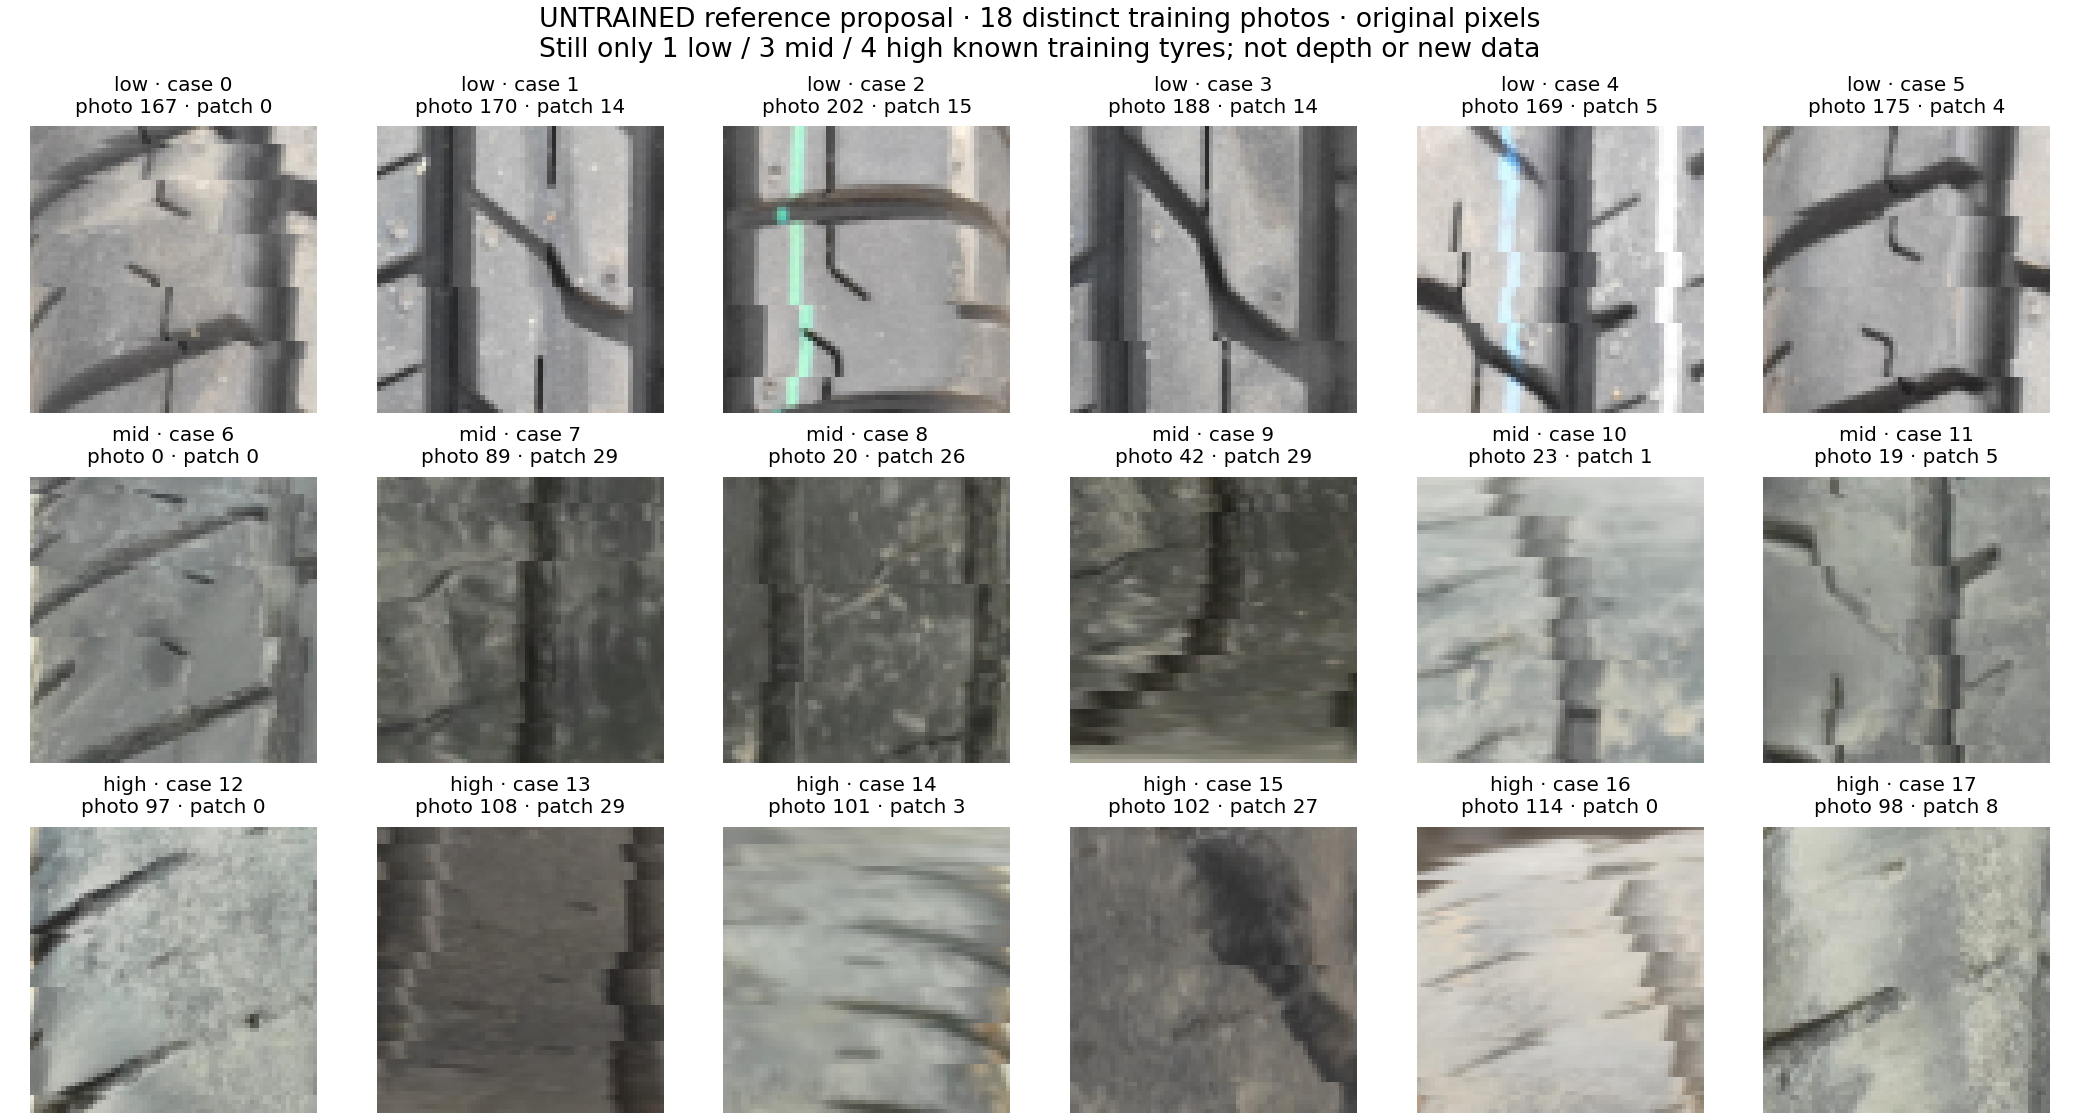

/kaggle/working/tread_two_nb10_appearance_gate/runtime/snapshots/snapshot-9121948eeeb242759d3790c2a613a708/report/Training_Gate_Explorer.html

Keep this executed NB10 for independent HF verification. No model has been trained or installed.


In [4]:
from IPython.display import display,FileLink,Image
import pandas as pd
latest=json.loads((RUNTIME/'LAST_SNAPSHOT.json').read_text())
SNAPSHOT=Path(latest['path'])
print(json.dumps(latest['receipt'],indent=2))
print((SNAPSHOT/'report/GATE_RESULT.json').read_text())
display(pd.read_csv(SNAPSHOT/'report/train_probe_metrics.csv'))
display(Image(filename=str(SNAPSHOT/'report/candidate_bank.png')))
display(FileLink(str(SNAPSHOT/'report/Training_Gate_Explorer.html')))
print('Keep this executed NB10 for independent HF verification. No model has been trained or installed.')